# 03 — Multilayer perceptron experiment on CICIDS2017

## Question

Can a feed-forward neural network classify network-flow attack families more accurately or efficiently than the existing Logistic Regression baseline and tree ensembles?

This notebook evaluates a multilayer perceptron (MLP) using the same CICIDS2017 label policy, leakage exclusions, duplicate removal, random split, time-ordered split, and macro-F1 metric used in `02_ensemble_models_cicids2017.ipynb`.

### Important comparison constraint

`MLPClassifier` in the installed scikit-learn version does not accept class weights. Training directly on the full dataset would allow the benign class to dominate, so this experiment uses class-aware training resampling while preserving each complete test set. Each training class contributes at most 50,000 rows; classes with fewer than 5,000 rows are sampled with replacement to reach 5,000. This makes the MLP experiment practical and more attentive to rare attacks, but its training time is not directly comparable with models trained on every training row.


In [1]:
import glob, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_fscore_support,
)

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

DATA = '../Data/archive/CICIDS2017_improved'
RESULTS_DIR = 'results'; os.makedirs(RESULTS_DIR, exist_ok=True)
RS = 42
MIN_PER_CLASS = 5_000
MAX_PER_CLASS = 50_000


## 1. Load and clean

The cleaning steps mirror notebook 02:

- fold `- Attempted` labels into `BENIGN`;
- exclude identifiers, timestamps, IP addresses, source port, and attempted-category code;
- replace infinite rates with a finite maximum;
- drop constant columns; and
- remove exact feature/label duplicates.


In [2]:
files = sorted(glob.glob(f'{DATA}/*.csv'))
if not files:
    raise FileNotFoundError(f'No CSV files found under {DATA}')

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
df['y'] = df['Label'].where(~df['Label'].str.endswith(' - Attempted'), 'BENIGN')
df['ts'] = pd.to_datetime(df['Timestamp'])

drop = [
    'id', 'Flow ID', 'Src IP', 'Dst IP', 'Src Port',
    'Timestamp', 'Attempted Category', 'Label'
]
X = df.drop(columns=drop + ['y', 'ts']).replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.max())
constant = [c for c in X if X[c].nunique() <= 1]
X = X.drop(columns=constant)
FEATURES = list(X.columns)

data = X.assign(y=df['y'].values, ts=df['ts'].values)
rows_before = len(data)
data = data.drop_duplicates(subset=FEATURES + ['y']).reset_index(drop=True)

print(f'Files: {len(files)}')
print(f'Features: {len(FEATURES)} | constants dropped: {constant}')
print(f'Duplicates removed: {rows_before - len(data):,}')
print(f'Rows retained: {len(data):,}')
display(data['y'].value_counts().rename('flows').to_frame())

del df, X


Files: 5
Features: 83 | constants dropped: []
Duplicates removed: 258,629
Rows retained: 1,841,347


,flows
y,
BENIGN,1434950
DoS Hulk,158468
DDoS,95144
Portscan,90620
Infiltration - Portscan,41179
DoS GoldenEye,7567
FTP-Patator,3972
DoS Slowloris,3859
SSH-Patator,2961


## 2. Create the same evaluation splits

The stratified random split is the conventional optimistic benchmark. The within-class time-ordered split is the primary result because it prevents later flows within an attack burst from entering training.


In [3]:
LABELS = sorted(data['y'].unique(), key=lambda c: (c != 'BENIGN', c))
encoder = LabelEncoder().fit(LABELS)
yall = encoder.transform(data['y'])

train_random, test_random = train_test_split(
    data.index, test_size=0.2, stratify=data['y'], random_state=RS
)
rank = data.groupby('y')['ts'].rank(method='first', pct=True)
train_time = data.index[rank <= 0.8]
test_time = data.index[rank > 0.8]

SPLITS = {
    'random': (np.asarray(train_random), np.asarray(test_random)),
    'time-ordered': (np.asarray(train_time), np.asarray(test_time)),
}
for name, (train_idx, test_idx) in SPLITS.items():
    print(f'{name:13s} train {len(train_idx):,} | test {len(test_idx):,}')

Xall = data[FEATURES].astype('float32').to_numpy()
del data


random        train 1,473,077 | test 368,270
time-ordered  train 1,473,071 | test 368,276


## 3. Feature transformation and class-aware resampling

Flow variables are highly skewed. A signed `log1p` transformation compresses extreme magnitudes while retaining the sign of fields such as header lengths. Standardization is then fitted only on the resampled training data. No information from the test set is used during preprocessing.


In [4]:
def resample_training_indices(train_idx, y, seed):
    rng = np.random.default_rng(seed)
    selected = []
    rows = []
    for class_id, class_name in enumerate(encoder.classes_):
        available = train_idx[y[train_idx] == class_id]
        target = min(MAX_PER_CLASS, max(MIN_PER_CLASS, len(available)))
        chosen = rng.choice(available, size=target, replace=len(available) < target)
        selected.append(chosen)
        rows.append({
            'class': class_name,
            'available_training_rows': len(available),
            'mlp_training_rows': target,
            'sampled_with_replacement': len(available) < target,
        })
    selected = np.concatenate(selected)
    rng.shuffle(selected)
    return selected, pd.DataFrame(rows)


def signed_log(array):
    return np.sign(array) * np.log1p(np.abs(array))


for split_name, (train_idx, _) in SPLITS.items():
    sampled_idx, sampling_table = resample_training_indices(train_idx, yall, RS)
    print(f'{split_name}: {len(sampled_idx):,} MLP training rows')
    display(sampling_table)


random: 288,997 MLP training rows


,class,available_training_rows,mlp_training_rows,sampled_with_replacement
0,BENIGN,1147960,50000,False
1,Botnet,589,5000,True
2,DDoS,76115,50000,False
3,DoS GoldenEye,6054,6054,False
4,DoS Hulk,126774,50000,False
5,DoS Slowhttptest,1392,5000,True
6,DoS Slowloris,3087,5000,True
7,FTP-Patator,3178,5000,True
8,Heartbleed,9,5000,True
9,Infiltration,29,5000,True


time-ordered: 288,996 MLP training rows


,class,available_training_rows,mlp_training_rows,sampled_with_replacement
0,BENIGN,1147960,50000,False
1,Botnet,588,5000,True
2,DDoS,76115,50000,False
3,DoS GoldenEye,6053,6053,False
4,DoS Hulk,126774,50000,False
5,DoS Slowhttptest,1392,5000,True
6,DoS Slowloris,3087,5000,True
7,FTP-Patator,3177,5000,True
8,Heartbleed,8,5000,True
9,Infiltration,28,5000,True


## 4. Train the MLP

The network has two hidden layers with 128 and 64 ReLU units. Adam optimization, mini-batches, L2 regularization, and early stopping control training time and overfitting. These are reasonable experiment settings rather than a tuned architecture.


In [5]:
results = []
predictions = {}
models = {}
loss_curves = {}
timing = []

for split_no, (split_name, (train_idx, test_idx)) in enumerate(SPLITS.items()):
    sampled_idx, sampling_table = resample_training_indices(train_idx, yall, RS + split_no)

    X_train = signed_log(Xall[sampled_idx])
    X_test = signed_log(Xall[test_idx])
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train).astype('float32')
    X_test = scaler.transform(X_test).astype('float32')

    model = MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation='relu',
        solver='adam',
        alpha=1e-4,
        batch_size=2048,
        learning_rate_init=1e-3,
        max_iter=50,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=5,
        random_state=RS,
        verbose=False,
    )

    start = time.perf_counter()
    model.fit(X_train, yall[sampled_idx])
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()
    predicted = model.predict(X_test)
    predict_seconds = time.perf_counter() - start

    precision, recall, f1, support = precision_recall_fscore_support(
        yall[test_idx], predicted,
        labels=encoder.transform(LABELS), zero_division=0
    )
    results.append(pd.DataFrame({
        'split': split_name,
        'model': 'MLP (128, 64)',
        'class': LABELS,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'support': support,
    }))
    timing.append({
        'split': split_name,
        'model': 'MLP (128, 64)',
        'training_rows': len(sampled_idx),
        'iterations': model.n_iter_,
        'fit_seconds': fit_seconds,
        'predict_seconds': predict_seconds,
    })
    predictions[split_name] = (test_idx, predicted)
    models[split_name] = (scaler, model)
    loss_curves[split_name] = model.loss_curve_

    print(
        f'{split_name:13s} iterations {model.n_iter_:2d} | '
        f'fit {fit_seconds:.1f}s | predict {predict_seconds:.1f}s | '
        f'macro F1 {f1.mean():.4f}'
    )

metrics = pd.concat(results, ignore_index=True)
timing = pd.DataFrame(timing)
metrics.to_csv(f'{RESULTS_DIR}/03_mlp_per_class_metrics.csv', index=False)
timing.to_csv(f'{RESULTS_DIR}/03_mlp_timing.csv', index=False)
display(timing.round(2))


random        iterations 29 | fit 21.1s | predict 0.2s | macro F1 0.8244


time-ordered  iterations 14 | fit 10.3s | predict 0.2s | macro F1 0.7312


,split,model,training_rows,iterations,fit_seconds,predict_seconds
0,random,"MLP (128, 64)",288997,29,21.05,0.17
1,time-ordered,"MLP (128, 64)",288996,14,10.29,0.17


## 5. Learning curves

Falling loss followed by early stopping indicates convergence under the selected iteration limit. The curves do not prove generalization; the held-out macro F1 remains the deciding measure.


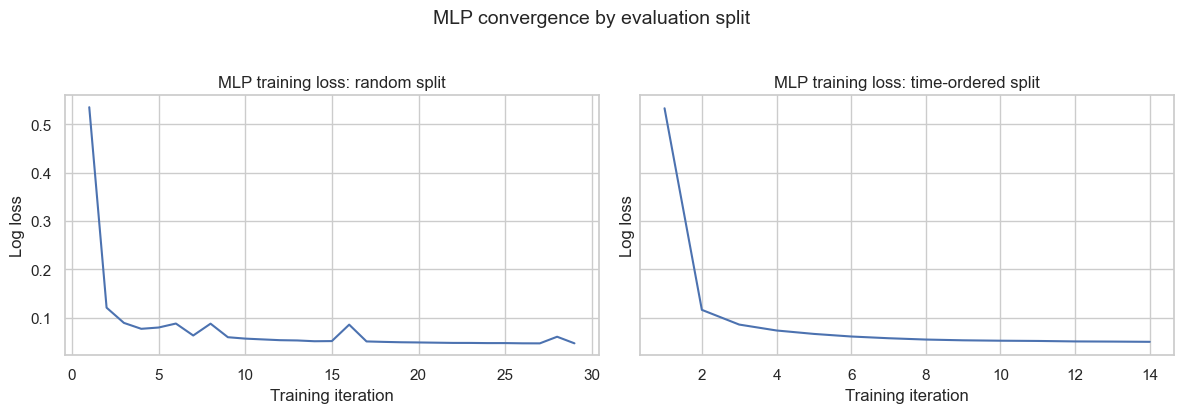

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, split_name in zip(axes, SPLITS):
    ax.plot(range(1, len(loss_curves[split_name]) + 1), loss_curves[split_name], color='#4C72B0')
    ax.set_title(f'MLP training loss: {split_name} split')
    ax.set_xlabel('Training iteration')
    ax.set_ylabel('Log loss')
fig.suptitle('MLP convergence by evaluation split', fontsize=14, y=1.03)
plt.tight_layout(); plt.show()


## 6. Evaluation metric

**Macro F1 is the primary metric.** F1 balances precision and recall within each class. Macro averaging then gives every class equal weight, preventing the large benign class from hiding failures on rare attacks. Weighted F1 is included as secondary context.


In [7]:
def summarise(group):
    return pd.Series({
        'macro_precision': group['precision'].mean(),
        'macro_recall': group['recall'].mean(),
        'macro_f1': group['f1'].mean(),
        'weighted_f1': np.average(group['f1'], weights=group['support']),
        'attack_macro_f1': group.loc[group['class'] != 'BENIGN', 'f1'].mean(),
    })

mlp_summary = metrics.groupby(['split', 'model']).apply(summarise, include_groups=False).reset_index()
mlp_summary.to_csv(f'{RESULTS_DIR}/03_mlp_summary.csv', index=False)
display(mlp_summary.round(4))


,split,model,macro_precision,macro_recall,macro_f1,weighted_f1,attack_macro_f1
0,random,"MLP (128, 64)",0.7882,0.9590,0.8244,0.9946,0.8127
1,time-ordered,"MLP (128, 64)",0.6896,0.9323,0.7312,0.9880,0.7136


## 7. Comparison with existing models

The saved results from notebook 02 are loaded rather than retraining every model. The time-ordered column is the primary comparison.


split,random,time-ordered
model,,
HistGB,0.9854,0.9236
LightGBM,0.9787,0.9182
XGBoost,0.9858,0.9108
ExtraTrees,0.9552,0.8924
RandomForest,0.9342,0.8908
"MLP (128, 64)",0.8244,0.7312
LogReg (baseline),0.7969,0.7278


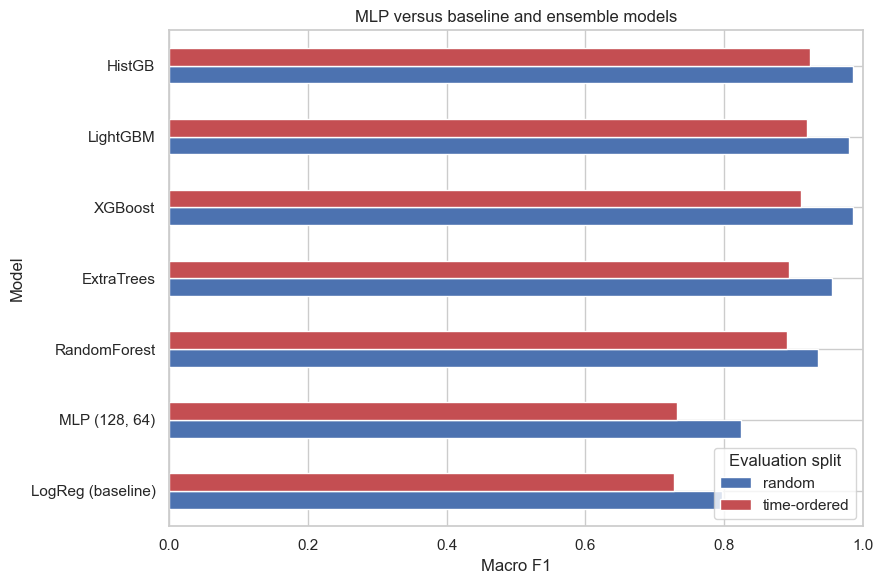

In [8]:
existing = pd.read_csv(f'{RESULTS_DIR}/02_summary.csv')
combined = pd.concat([
    existing[['split', 'model', 'macro_f1', 'weighted_f1', 'attack_macro_f1']],
    mlp_summary[['split', 'model', 'macro_f1', 'weighted_f1', 'attack_macro_f1']],
], ignore_index=True)

comparison = combined.pivot(index='model', columns='split', values='macro_f1')
comparison = comparison.sort_values('time-ordered', ascending=False)
display(comparison.round(4))

ax = comparison.sort_values('time-ordered').plot.barh(figsize=(9, 6), color=['#4C72B0', '#C44E52'])
ax.set_xlim(0, 1)
ax.set_xlabel('Macro F1')
ax.set_ylabel('Model')
ax.set_title('MLP versus baseline and ensemble models')
ax.legend(title='Evaluation split')
plt.tight_layout(); plt.show()


## 8. Per-class MLP performance

Rare classes have very small test support. Their individual F1 values should be treated as unstable even when resampling produces a high score.


,precision,recall,f1,support
class,,,,
BENIGN,0.9999,0.9988,0.9993,286990
Botnet,0.9932,1.0000,0.9966,147
DDoS,0.9997,0.9999,0.9998,19029
DoS GoldenEye,0.9479,0.9987,0.9726,1513
DoS Hulk,0.9995,0.9998,0.9997,31694
DoS Slowhttptest,0.8900,1.0000,0.9418,348
DoS Slowloris,0.9822,0.9987,0.9904,772
FTP-Patator,0.9987,1.0000,0.9994,794
Heartbleed,0.2000,1.0000,0.3333,2


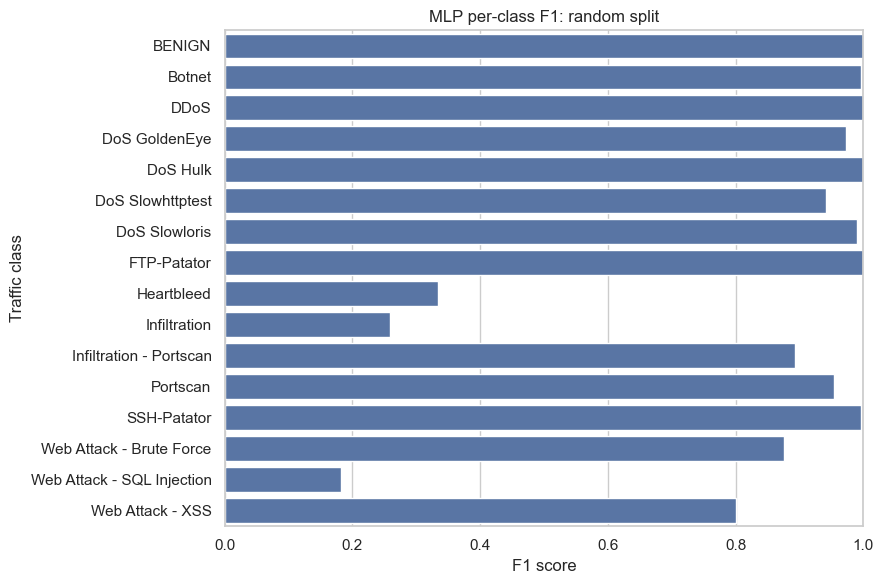

,precision,recall,f1,support
class,,,,
BENIGN,0.9990,0.9917,0.9953,286990
Botnet,0.6607,1.0000,0.7957,148
DDoS,0.9979,0.9989,0.9984,19029
DoS GoldenEye,0.9176,0.9855,0.9503,1514
DoS Hulk,0.9976,0.9997,0.9986,31694
DoS Slowhttptest,0.3568,0.4799,0.4093,348
DoS Slowloris,0.9089,0.6334,0.7466,772
FTP-Patator,0.9925,1.0000,0.9962,795
Heartbleed,0.5000,1.0000,0.6667,3


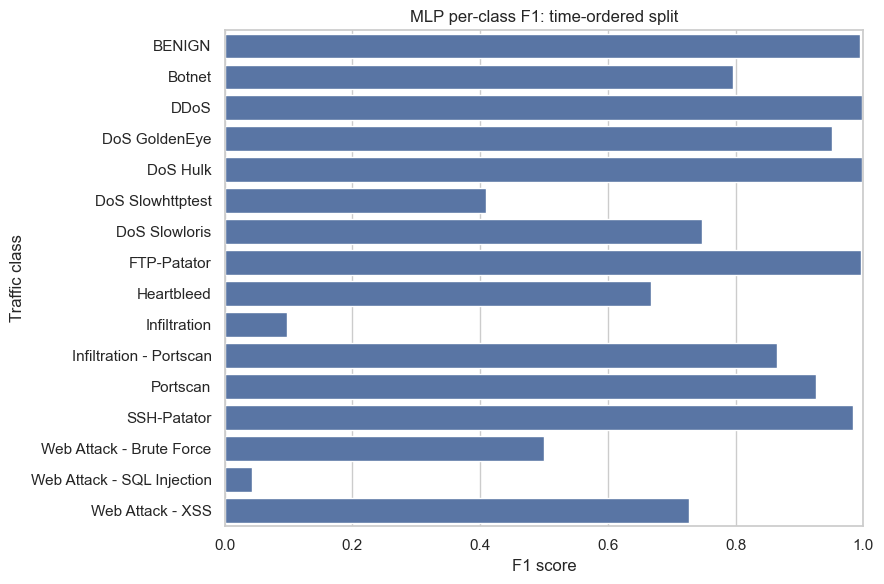

In [9]:
for split_name in SPLITS:
    table = metrics[metrics['split'] == split_name].set_index('class')
    display(table[['precision', 'recall', 'f1', 'support']].round(4))

    fig, ax = plt.subplots(figsize=(9, 6))
    sns.barplot(data=table.reset_index(), y='class', x='f1', color='#4C72B0', ax=ax)
    ax.set_xlim(0, 1)
    ax.set_xlabel('F1 score')
    ax.set_ylabel('Traffic class')
    ax.set_title(f'MLP per-class F1: {split_name} split')
    plt.tight_layout(); plt.show()


## 9. Time-ordered confusion matrix

The matrix is row-normalized by color so recall is visible for both large and small classes. Cell annotations show raw counts.


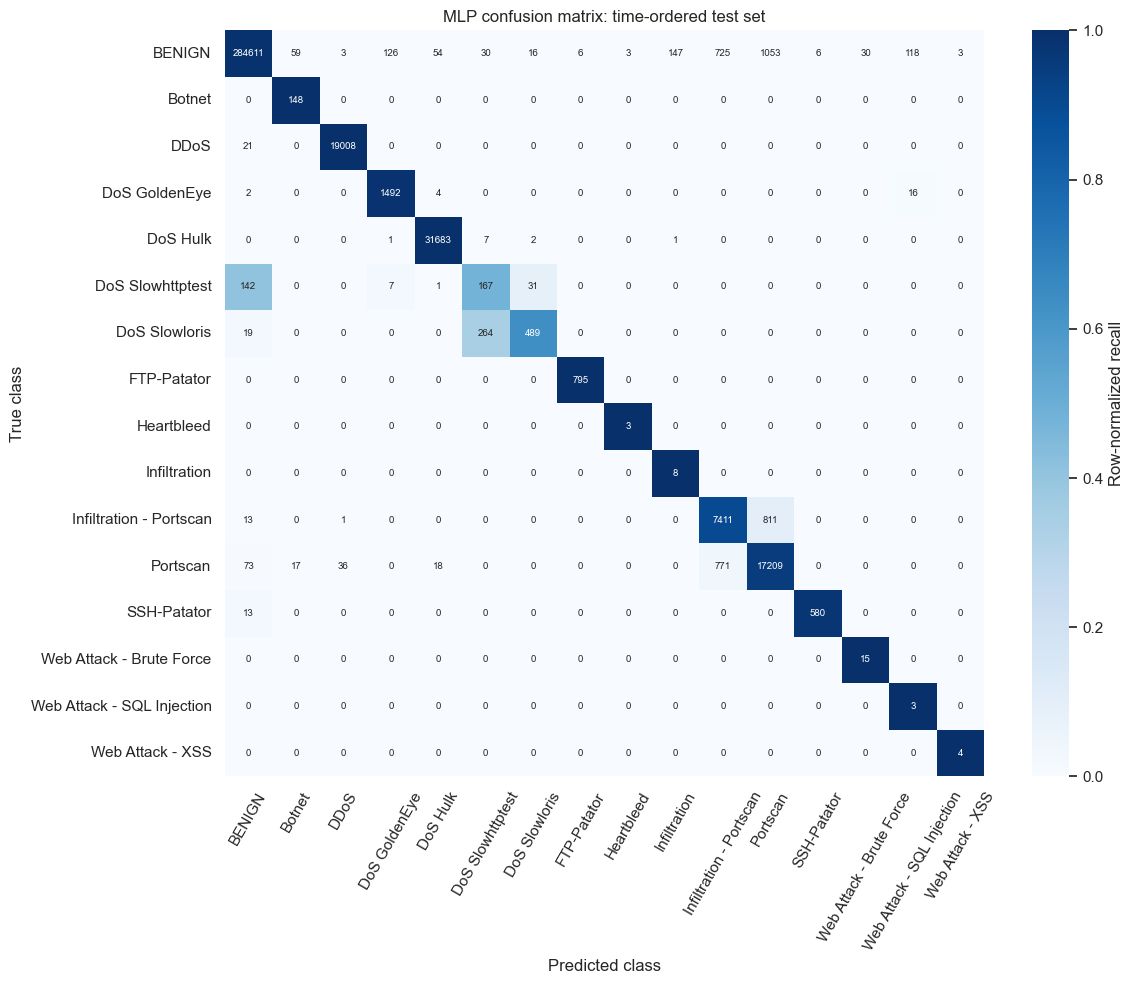

In [10]:
test_idx, predicted = predictions['time-ordered']
matrix = confusion_matrix(
    yall[test_idx], predicted,
    labels=encoder.transform(LABELS)
)
normalized = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    normalized, annot=matrix, fmt='d', cmap='Blues', vmin=0, vmax=1,
    xticklabels=LABELS, yticklabels=LABELS,
    annot_kws={'fontsize': 7}, cbar_kws={'label': 'Row-normalized recall'}, ax=ax
)
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')
ax.set_title('MLP confusion matrix: time-ordered test set')
ax.tick_params(axis='x', labelrotation=60)
ax.tick_params(axis='y', labelrotation=0)
plt.tight_layout(); plt.show()


## 10. Detailed classification reports


In [11]:
for split_name, (test_idx, predicted) in predictions.items():
    print(f'===== MLP | {split_name} split =====')
    print(classification_report(
        yall[test_idx], predicted,
        labels=encoder.transform(LABELS),
        target_names=LABELS,
        digits=4, zero_division=0,
    ))


===== MLP | random split =====
                            precision    recall  f1-score   support

                    BENIGN     0.9999    0.9988    0.9993    286990
                    Botnet     0.9932    1.0000    0.9966       147
                      DDoS     0.9997    0.9999    0.9998     19029
             DoS GoldenEye     0.9479    0.9987    0.9726      1513
                  DoS Hulk     0.9995    0.9998    0.9997     31694
          DoS Slowhttptest     0.8900    1.0000    0.9418       348
             DoS Slowloris     0.9822    0.9987    0.9904       772
               FTP-Patator     0.9987    1.0000    0.9994       794
                Heartbleed     0.2000    1.0000    0.3333         2
              Infiltration     0.1667    0.5714    0.2581         7
   Infiltration - Portscan     0.9073    0.8797    0.8933      8236
                  Portscan     0.9443    0.9630    0.9535     18124
               SSH-Patator     0.9916    1.0000    0.9958       592
  Web Attack - B

## 11. Conclusion

The MLP reaches **0.8244 macro F1** on the random split and **0.7312** on the time-ordered split. It slightly exceeds Logistic Regression on the primary time-ordered measure (0.7312 versus 0.7278), but the improvement is only 0.0033. It remains far behind HistGradientBoosting at 0.9236 and the other tree ensembles, which range from 0.8908 to 0.9182.

The MLP fitted in 10.3 seconds for the time-ordered experiment and predicted the full test set in 0.17 seconds. That training time is not a controlled speed comparison: the neural network used a 288,996-row class-aware resample, while the notebook 02 models trained on approximately 1.47 million rows. The resampling step also repeats extremely rare classes and may increase overfitting.

### Answer to the experiment question

For these aggregated tabular flow features, the tested MLP does **not** solve the classification problem more effectively than gradient-boosted trees. Its score is effectively tied with the linear baseline and substantially below the best ensemble. The result supports keeping HistGradientBoosting as the leading Module 24 candidate.

Neural networks may become more competitive if the project later uses raw packet sequences, sequences of related flows, learned categorical embeddings, or a larger architecture with systematic tuning. Cross-year evaluation remains more important than a small within-year score change because it tests whether the detector learned attack behavior rather than CICIDS2017-specific hosts and schedules.
